In [ ]:
# import duckdb
# import pandas as pd
# import shap
# from joblib import load
# import matplotlib.pyplot as plt
# from matplotlib.patches import Patch
# from config import DB_PATH, CURRENT_SEASON_ID
# from feature_engineering import build_features
# import os
# from datetime import datetime, timezone
# pd.set_option("display.max_colwidth", None)
# pd.set_option("display.max_columns", None)
# pd.set_option("display.max_rows", None)
# # --------------------------------------------------
# # Load model bundle
# # --------------------------------------------------

# script_dir = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
# model_path = os.path.join(script_dir, "models", "playoff_models_wc_field_pressure_v4.joblib")

# bundle = load(model_path)
# xgb_pipeline = bundle["xgb_pipeline"]
# FEATURE_COLS = bundle["features"]

# xgb_model = xgb_pipeline.named_steps["model"]
# scaler = xgb_pipeline.named_steps.get("scaler", None)

# # --------------------------------------------------
# # Pull latest snapshot (one row per team)
# # --------------------------------------------------
# con = duckdb.connect(DB_PATH)

# # df_raw = con.execute(f"""
# # SELECT *
# # FROM team_daily_stats
# # WHERE season_id = {CURRENT_SEASON_ID}
# # QUALIFY ROW_NUMBER() OVER (
# #     PARTITION BY team_id
# #     ORDER BY game_date DESC
# # ) = 1
# # """).df()


# df_raw = con.execute(f"""
# SELECT *
# FROM team_daily_stats
# WHERE season_id = {CURRENT_SEASON_ID}
# ORDER BY game_date, team_id
# """).df()


# # df_scored = con.execute(f"""
# #                         SELECT *
# # FROM playoff_daily_predictions
# # WHERE season_id = {CURRENT_SEASON_ID}
# # QUALIFY ROW_NUMBER() OVER (
# #     PARTITION BY team_id
# #     ORDER BY game_date DESC
# # ) = 1
# # """).df()

# df_scored = con.execute(f"""
# SELECT *
# FROM playoff_daily_predictions
# WHERE season_id = {CURRENT_SEASON_ID}
# ORDER BY game_date, team_id
# """).df()


# assert df_raw["team_id"].nunique() == 32
# assert df_scored["team_id"].nunique() == 32
# # --------------------------------------------------
# # Feature engineering
# # --------------------------------------------------
# df_features = build_features(df_raw)


# df_features = df_features.merge(
#     df_scored[[
#         "team_id",
#         "game_date",
#         "playoff_prob",
#         "playoff_prob_xgb",
#         "playoff_prob_rf",
#         "playoff_prob_display",
#         "playoff_tier"
#     ]],
#     # on="team_id",
#     on=["team_id", "game_date"],
#     how="left"
# )

# assert df_features["playoff_prob"].notna().all(), "Missing probabilities after merge"
# # --------------------------------------------------
# # Build feature matrix (must match training features)
# # --------------------------------------------------
# LEAK_COLS = [
#     "game_id","game_date","date",
#     "clinch_type","made_playoffs",
#     "team_name","opponent","season_id"
# ]
# ID_COLS = ["team_id","opponent_id","tri_code"]

# X = (
#     df_features
#       .drop(columns=LEAK_COLS + ID_COLS, errors="ignore")
#       .select_dtypes(include="number")
#       .reindex(columns=FEATURE_COLS, fill_value=0)
#       .fillna(0)
# )




# # ---- Build the exact numeric matrix you want to explain with SHAP
# if scaler is not None:
#     X_shap_scaled = pd.DataFrame(
#         scaler.transform(X),
#         columns=X.columns,
#         index=X.index
#     )
# else:
#     X_shap_scaled  = X

# # --------------------------------------------------
# # SHAP
# # --------------------------------------------------
# explainer = shap.TreeExplainer(xgb_model)
# shap_expl = explainer(X_shap_scaled)  # <-- Explanation object

# # --------------------------------------------------
# # Explain function
# # --------------------------------------------------
# def explain_team(
#     team_code: str,
#     current_df: pd.DataFrame,
#     X_shap_scaled: pd.DataFrame,
#     shap_expl,
#     feature_cols: list,
#     n: int = 8
# ):
#     team_mask = current_df["tri_code"].str.upper() == team_code.upper()
#     if not team_mask.any():
#         raise ValueError(f"Team {team_code} not found")

#     row_idx = current_df.loc[team_mask].index[-1]

#     if row_idx not in X_shap_scaled.index:
#         raise ValueError(
#             f"Row index {row_idx} not found in X_shap_scaled. "
#             "Make sure you didn't reset index on either df."
#         )

#     row_pos = X_shap_scaled.index.get_loc(row_idx)

#     shap_row = pd.Series(
#         shap_expl.values[row_pos, :],
#         index=feature_cols
#     ).sort_values()

#     most_harmful = shap_row.head(n)
#     most_helpful = shap_row.tail(n)

#     # season stage
#     if "season_bucket" in current_df.columns:
#         season_stage = current_df.loc[row_idx, "season_bucket"]
#     elif "games_played" in current_df.columns:
#         gp = current_df.loc[row_idx, "games_played"]
#         season_stage = "early" if gp <= 20 else "mid" if gp <= 50 else "late"
#     else:
#         season_stage = "unknown"

#     # probability (now exists because we added playoff_prob)
#     playoff_prob = current_df.loc[row_idx, "playoff_prob"] if "playoff_prob" in current_df.columns else None

#     header = f"\n📊 {team_code.upper()} PLAYOFF EXPLANATION ({season_stage.upper()} SEASON)\n"
#     if playoff_prob is not None and pd.notna(playoff_prob):
#         header += f"Model Odds: {playoff_prob:.1%}\n"
#     print(header)

#     print("🔻 Most Harmful Drivers")
#     display(most_harmful.round(3))

#     print("\n🔺 Most Helpful Drivers")
#     display(most_helpful.round(3))

#     return most_helpful, most_harmful



In [198]:
con.close()
print("DuckDB connection closed.")

DuckDB connection closed.


# Graphs

In [199]:
import os
import json
import pandas as pd
from datetime import datetime, timezone
import numpy as np
import duckdb
DB_PATH = r"C:\Users\kjchr\Desktop\hockey\new_hockey_env\API data\duckdb\nhl_data.duckdb"
con = duckdb.connect(DB_PATH) 
print("Connected:", DB_PATH)

try:
    import shap
    SHAP_AVAILABLE = True
except ImportError:
    SHAP_AVAILABLE = False
    print("⚠️ SHAP not installed — using permutation importance fallback.")


# Suppress SettingWithCopyWarning
pd.options.mode.chained_assignment = None
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)


Connected: C:\Users\kjchr\Desktop\hockey\new_hockey_env\API data\duckdb\nhl_data.duckdb


In [ ]:
# con.execute("DROP TABLE IF EXISTS playoff_shap_values")

In [193]:
# con.execute('select* from playoff_daily_predictions').df()
con.execute("SHOW TABLES").fetchdf()

,name
0,all_clinch_history
1,all_final_standings
2,all_game_summary
3,all_goalie_games
4,all_pk
5,all_play_by_play
6,all_pp
7,all_prediction_data_agg
8,all_standings_daily
9,all_teams


In [139]:
daily_odds = con.execute('select * from playoff_daily_predictions').fetch_df()
daily_odds.head()

,season_id,game_date,team_id,tri_code,conference,division,conference_rank,division_rank,wildcard_rank,points,projected_points,playoff_prob,playoff_prob_xgb,playoff_prob_rf,playoff_prob_display,playoff_tier,season_bucket,model_name,model_version,model_run_ts
0,20252026,2025-10-07,1,NJD,None,None,<NA>,<NA>,<NA>,<NA>,NaN,0.142531,0.059638,0.225424,0.142531,Long Shot,late,playoff_models_xgb_rf,wc_field_pressure_v4,2026-03-15 14:46:20.565514
1,20252026,2025-10-08,1,NJD,None,None,<NA>,<NA>,<NA>,<NA>,NaN,0.142531,0.059638,0.225424,0.142531,Long Shot,late,playoff_models_xgb_rf,wc_field_pressure_v4,2026-03-15 14:46:20.565514
2,20252026,2025-10-09,1,NJD,Eastern,Metropolitan,14,8,8,0,0.0,0.564346,0.590218,0.538474,0.528956,Bubble,early,playoff_models_xgb_rf,wc_field_pressure_v4,2026-03-15 14:46:20.565514
3,20252026,2025-10-11,1,NJD,Eastern,Metropolitan,10,6,4,2,82.0,0.583571,0.630817,0.536325,0.537607,Bubble,early,playoff_models_xgb_rf,wc_field_pressure_v4,2026-03-15 14:46:20.565514
4,20252026,2025-10-12,1,NJD,Eastern,Metropolitan,10,6,4,2,82.0,0.583571,0.630817,0.536325,0.537607,Bubble,early,playoff_models_xgb_rf,wc_field_pressure_v4,2026-03-15 14:46:20.565514


In [140]:
bs_daily_odds = daily_odds[daily_odds['team_id']==6]
bs_daily_odds["season_day"] = (
    bs_daily_odds
    .sort_values(["team_id", "game_date"])
    .groupby(["season_id", "team_id"])
    .cumcount() + 1
)



In [141]:
all_games  = con.execute('select* from all_game_summary where season_id = 20252026').df()


In [142]:

bs_games = all_games[
    (all_games['away_tri_code'] == "BOS") |
    (all_games['home_tri_code'] == "BOS")
]

bs_games = bs_games[['game_id','game_date', 'gameState']]
bs_games = bs_games[bs_games['gameState']=='OFF'].reset_index(drop=True)
bs_games.head()


,game_id,game_date,gameState
0,2025020005,2025-10-08,OFF
1,2025020008,2025-10-09,OFF
2,2025020024,2025-10-11,OFF
3,2025020040,2025-10-13,OFF
4,2025020069,2025-10-16,OFF


In [143]:
game_dates = set(bs_games["game_date"])

bs_daily_odds["is_game_day"] = (
    bs_daily_odds["game_date"].isin(game_dates)
)

In [144]:
# bs_daily_odds = bs_daily_odds.sort_values(["team_id", "game_date"])

# bs_daily_odds["game_no"] = (
#     bs_daily_odds["is_game_day"]
#     .groupby([bs_daily_odds["season_id"], bs_daily_odds["team_id"]])
#     .cumsum()
# )
bs_daily_odds.head()

,season_id,game_date,team_id,tri_code,conference,division,conference_rank,division_rank,wildcard_rank,points,projected_points,playoff_prob,playoff_prob_xgb,playoff_prob_rf,playoff_prob_display,playoff_tier,season_bucket,model_name,model_version,model_run_ts,season_day,is_game_day
670,20252026,2025-10-07,6,BOS,None,None,<NA>,<NA>,<NA>,<NA>,NaN,0.142531,0.059638,0.225424,0.142531,Long Shot,late,playoff_models_xgb_rf,wc_field_pressure_v4,2026-03-15 14:46:20.565514,1,False
671,20252026,2025-10-08,6,BOS,Eastern,Atlantic,3,2,0,2,164.0,0.652515,0.755113,0.549918,0.568632,Bubble,early,playoff_models_xgb_rf,wc_field_pressure_v4,2026-03-15 14:46:20.565514,2,True
672,20252026,2025-10-09,6,BOS,Eastern,Atlantic,3,2,0,4,164.0,0.654582,0.755113,0.554050,0.569562,Bubble,early,playoff_models_xgb_rf,wc_field_pressure_v4,2026-03-15 14:46:20.565514,3,True
673,20252026,2025-10-11,6,BOS,Eastern,Atlantic,2,2,0,6,164.0,0.656099,0.756924,0.555273,0.570244,Bubble,early,playoff_models_xgb_rf,wc_field_pressure_v4,2026-03-15 14:46:20.565514,4,True
674,20252026,2025-10-12,6,BOS,Eastern,Atlantic,2,2,0,6,164.0,0.656099,0.756924,0.555273,0.570244,Bubble,early,playoff_models_xgb_rf,wc_field_pressure_v4,2026-03-15 14:46:20.565514,5,False


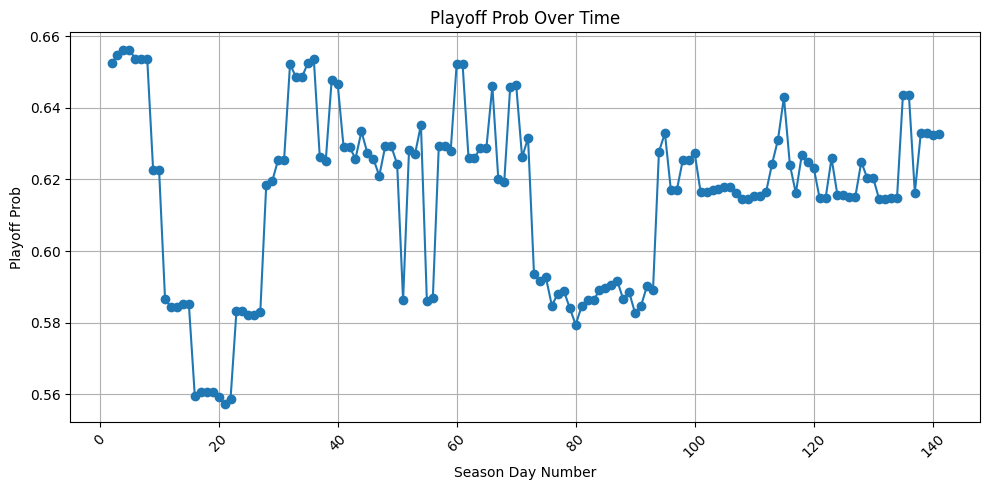

In [145]:
import matplotlib.pyplot as plt

bs_daily_odds=bs_daily_odds[bs_daily_odds['season_day']>1]

# Plot
plt.figure(figsize=(10, 5))
plt.plot(bs_daily_odds['season_day'], bs_daily_odds['playoff_prob'], marker='o')
plt.title("Playoff Prob Over Time")
plt.xlabel("Season Day Number")
plt.ylabel("Playoff Prob")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

# SHAP

In [221]:
df_present=con.execute('select * from playoff_shap_values').fetch_df()
# df_present=con.execute('select * from team_daily_stats').fetch_df()
# df_present[df_present['team_id']==6 & df_present['season_id']==20252026]
df_present[df_present['team_id']==6].head()

# df_present[
#     (df_present['team_id'] == 6) & (df_present['season_id']==20252026)
# ]

,season_id,game_date,team_id,tri_code,game_win,wins_before,games_before,win_pct_before,sos_past,sos_future,pp_opp,pp_opp_pg,pp_toi,pp_gpg,pp_net_g,pp_net_gpg,pp_pct,pp_net_pct,sh_ga_pg,times_sh_pg,pk_net_pct,pk_pct,pk_net_g,pk_net_gpg,pk_toi,pp_ga_pg,sh_gf_pg,c_pp_opps,c_pp_net_g,ppng_rank,c_pp_ga,c_times_sh,pk_rank,rush_shots_for,rush_shots_against,rush_shot_differential,c_rush_shots_for,c_rush_shots_against,c_rush_diff,rush_for_per_game,rush_against_per_game,rush_diff_per_game,shot_attempts_for,shot_attempts_against,shot_attempts_differential,corsi_for,corsi_against,corsi_diff,c_shots_diff,games_played,shot_attempts_for_per_game,shot_attempts_against_per_game,shots_diff_per_game,SCF,SCSF,SCGF,SCA,HDCF,MDCF,LDCF,HDCA,MDCA,LDCA,HDCF_pct,HDCA_pct,MDCF_pct,MDCA_pct,LDCF_pct,LDCA_pct,c_SCF,c_SCSF,c_SCGF,c_SCA,SCF_pg,SCA_pg,c_HDCF,c_HDCA,c_MDCF,c_MDCA,c_LDCF,c_LDCA,shot_pct,sv_pct,pdo,c_goals_for,c_hd_sog,c_md_sog,c_ld_sog,c_hd_goals,c_md_goals,c_ld_goals,c_goals_against,c_hd_against,c_md_against,c_ld_against,c_shot_pct,c_sv_pct,c_pdo,c_shots_for,c_shots_against,c_corsi_for,c_corsi_against,c_corsi_diff,corsi_diff_per_game,games_remaining,wins,wins_pctg,losses,ot_losses,rotw,rotw_pctg,rw,so_losses,so_wins,points,points_pct,projected_points,in_playoff_spot,gf_pctg,goal_diff,goal_diff_pctg,streak_count,last_10_gp,last_10_wins,last_10_losses,last_10_otl,last_10_points,last_10_gf,last_10_ga,last_10_goal_diff,last_10_rotw,last_10_rw,home_gp,home_wins,home_losses,home_otlosses,home_rotw,home_rw,home_points,home_gf,home_ga,home_goal_diff,road_gp,road_wins,road_losses,road_ot_losses,road_rotw,road_rw,road_points,road_gf,road_ga,road_goal_diff,division_rank,conference_rank,wildcard_rank,ot_wins,overtimes,ot_games_pct,pt_pct_x_sos,gaa_x_sv,gd_x_rushdiff,pk_load_x_pk_pct,conference_team_count,conf_playoff_chance_baseline,streak_signed,wc2_points,wc2_points_pct,wc_points_margin,wc_points_pct_margin,in_wc_spot,in_div_top3,on_wc_bubble,wc_teams_within_2pts,wc_teams_within_4pts,wc_teams_within_6pts,model_version,model_run_ts
343,20252026,2025-10-08,6,BOS,0.0,-0.000061,0.000057,-0.096887,-0.046075,0.438218,0.000042,-0.000034,-0.000156,4.571590e-04,0.0,0.001147,0.000049,0.0,-0.000055,0.000486,0.000037,0.000060,0.0,-5.588080e-05,0.000016,-0.000007,0.0,0.001761,-0.066137,0.131474,-0.000818,-0.005986,0.117980,0.000122,0.000066,0.000004,-0.001150,0.012494,0.002826,-0.063420,-0.057284,-0.004976,0.000072,0.000016,-1.526910e-04,-0.000115,-0.000186,-0.002478,0.002655,0.0,-0.019957,-0.330582,0.041617,0.000216,0.000259,-0.000191,-0.000149,-0.000438,0.000027,0.000386,-0.000022,-0.000080,0.002365,-0.000103,-4.143516e-06,-0.000101,0.0,0.000007,0.000002,-0.002291,0.00001,-0.003671,0.006667,-0.129595,0.054081,-0.064123,-0.001860,-0.000426,-0.000129,0.000673,0.0,-0.000453,0.000383,0.002271,0.0,-0.000651,-0.001977,0.001391,0.005116,-0.000145,0.001762,0.001265,0.000551,-0.001004,0.000042,0.160004,0.193607,-0.008506,-0.000024,0.0,0.000964,0.000879,-0.003292,-0.295157,0.000002,-0.000331,0.203805,0.006322,0.008156,-0.004930,0.010294,-0.083100,0.009840,-0.001680,0.0,0.147700,0.007544,0.0,0.026111,-0.000940,0.033031,0.000004,0.0,-0.000002,0.000020,0.000281,-0.000177,0.005238,0.012222,-0.000096,-0.000228,-0.002322,0.001055,-0.000460,0.005427,0.003987,-0.004124,-0.019298,-0.000276,0.002568,0.001091,-0.031477,-0.000140,-0.003981,-0.008552,-0.004379,-0.027941,-0.023367,-0.026267,0.002801,0.007427,0.032675,0.140069,0.185146,0.056497,-0.001895,0.002913,0.002728,0.003076,0.003197,0.000083,0.000016,0.008853,-0.017271,0.000007,-0.001628,-0.003502,-0.026624,0.003292,0.0,0.0,0.000688,0.000995,0.002320,-0.001162,wc_field_pressure_v4,2026-03-21 22:11:27.670631
344,20252026,2025-10-09,6,BOS,0.0,0.000004,0.000077,0.149843,-0.126358,0.454081,0.000016,0.000078,-0.000056,1.801522e-04,0.0,0.000270,-0.000017,0.0,-0.000048,-0.000292,0.000035,0.000032,0.0,5.065340e-08,-0.000058,-0.000003,0.0,0.002319,-0.082560,0.053914,-0.000957,-0.003880,0.088717,-0.000058,0.000169,-0.000068,-0.001822,0.0039

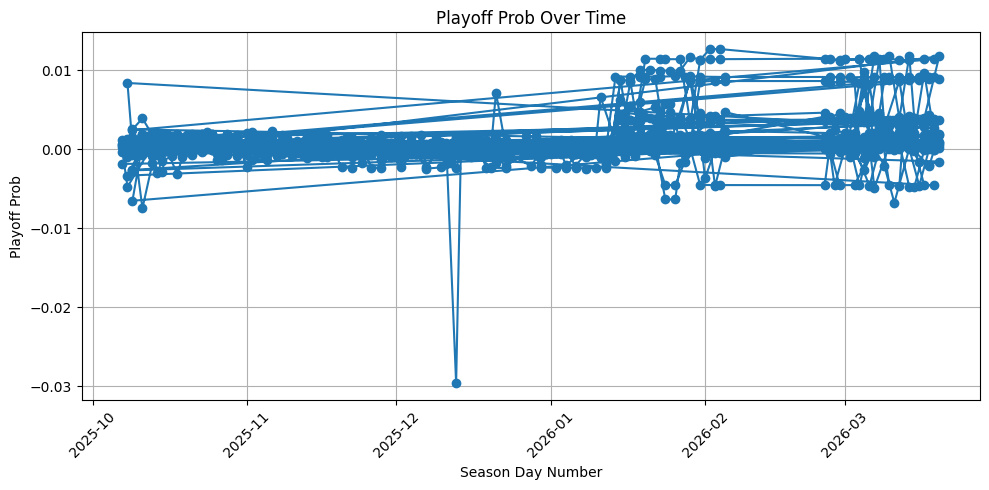

In [222]:
import matplotlib.pyplot as plt


# Plot
plt.figure(figsize=(10, 5))
plt.plot(df_present['game_date'], df_present['times_sh_pg'], marker='o')
plt.title("Playoff Prob Over Time")
plt.xlabel("Season Day Number")
plt.ylabel("Playoff Prob")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [201]:
META_COLS = [
    "season_id", "game_date", "team_id", "tri_code",
    "model_version", "model_run_ts"
]

shap_cols = [col for col in df_present.columns if col not in META_COLS]

print(len(shap_cols), "SHAP columns found")

171 SHAP columns found


In [202]:
zero_cols = [
    col for col in shap_cols
    if (df_present[col] == 0).all()
]

print("All-zero SHAP features:", len(zero_cols))
print(zero_cols[:20])

All-zero SHAP features: 15
['game_win', 'pp_net_g', 'pp_net_pct', 'pk_net_g', 'sh_gf_pg', 'games_played', 'MDCA_pct', 'c_LDCA', 'c_goals_for', 'c_shots_against', 'points', 'in_playoff_spot', 'last_10_gp', 'in_wc_spot', 'in_div_top3']


In [203]:

# --------------------------------------------------
# Identify SHAP columns (exclude metadata)
# --------------------------------------------------
META_COLS = [
    "season_id", "game_date", "team_id", "tri_code",
    "model_version", "model_run_ts"
]

shap_cols = [col for col in df_present.columns if col not in META_COLS]

# --------------------------------------------------
# Build SHAP summary table
# --------------------------------------------------
def explain_all_rows(df_present, shap_df, n=10):

    results = []

    feature_names = shap_df.columns.to_numpy()
    shap_values = shap_df.to_numpy()

    for i in range(len(df_present)):

        row_vals = shap_values[i]
        row_info = df_present.iloc[i]

        # top / bottom
        top_idx = np.argpartition(row_vals, -n)[-n:]
        bottom_idx = np.argpartition(row_vals, n)[:n]

        top_idx = top_idx[np.argsort(row_vals[top_idx])]
        bottom_idx = bottom_idx[np.argsort(row_vals[bottom_idx])]

        # absolute importance
        abs_idx = np.argsort(np.abs(row_vals))[-n:]
        abs_idx = abs_idx[np.argsort(np.abs(row_vals[abs_idx]))]

        base_info = {
            "season_id": row_info["season_id"],
            "game_date": pd.to_datetime(row_info["game_date"]),
            "team_id": row_info["team_id"],
            "tri_code": row_info["tri_code"],
            "playoff_prob": row_info.get("playoff_prob", None),
            "snapshot_id": f"{row_info['season_id']}_{row_info['game_date']}"
        }

        # helpful
        for rank, j in enumerate(top_idx[::-1], 1):
            results.append({
                **base_info,
                "feature": feature_names[j],
                "feature_value": None,  # not available (you only have SHAP)
                "shap_value": row_vals[j],
                "direction": "helpful",
                "rank": rank
            })

        # harmful
        for rank, j in enumerate(bottom_idx, 1):
            results.append({
                **base_info,
                "feature": feature_names[j],
                "feature_value": None,
                "shap_value": row_vals[j],
                "direction": "harmful",
                "rank": rank
            })

        # absolute importance
        for rank, j in enumerate(abs_idx[::-1], 1):
            results.append({
                **base_info,
                "feature": feature_names[j],
                "feature_value": None,
                "shap_value": row_vals[j],
                "direction": "absolute",
                "rank": rank
            })

    return pd.DataFrame(results)

# --------------------------------------------------
# Create shap_summary
# --------------------------------------------------
shap_summary = explain_all_rows(
    df_present=df_present,
    shap_df=df_present[shap_cols],
    n=10
)

# --------------------------------------------------
# Explain a team snapshot
# --------------------------------------------------
def explain_team_snapshot(shap_summary, team, game_date):

    game_date = pd.to_datetime(game_date)

    df = shap_summary[
        (shap_summary["tri_code"].str.upper() == team.upper()) &
        (pd.to_datetime(shap_summary["game_date"]) == game_date)
    ]

    if df.empty:
        print(f"❌ No data for {team} on {game_date.date()}")
        return

    helpful = df[df["direction"] == "helpful"].sort_values("rank")
    harmful = df[df["direction"] == "harmful"].sort_values("rank")

    print(f"\n📈 {team} — {game_date.date()}")

    print("\n🔥 Top Drivers (Helpful):")
    print(helpful[["feature", "shap_value"]])

    print("\n❄️ Biggest Risks (Harmful):")
    print(harmful[["feature", "shap_value"]])

# --------------------------------------------------
# Example usage (AUTO latest date for team)
# --------------------------------------------------
team = "BOS"

latest_date = shap_summary[
    shap_summary["tri_code"] == team
]["game_date"].max()

explain_team_snapshot(shap_summary, team, latest_date)


📈 BOS — 2026-03-19

🔥 Top Drivers (Helpful):
               feature  shap_value
12330        wins_pctg    0.314240
12331       c_shot_pct    0.292603
12332         c_sv_pct    0.281716
12333       sos_future    0.266480
12334        goal_diff    0.249116
12335  conference_rank    0.213564
12336       points_pct    0.149257
12337       c_pp_net_g    0.142255
12338   win_pct_before    0.098787
12339   home_goal_diff    0.097373

❄️ Biggest Risks (Harmful):
                              feature  shap_value
12340                wc_points_margin   -0.228783
12341                          SCF_pg   -0.222065
12342  shot_attempts_against_per_game   -0.208280
12343                   division_rank   -0.195280
12344                          SCA_pg   -0.128745
12345               rush_for_per_game   -0.117124
12346                    ot_games_pct   -0.091087
12347           rush_against_per_game   -0.088232
12348                         gf_pctg   -0.079912
12349                       so_losses   

In [204]:
# # --------------------------------------------------
# # Run it
# # --------------------------------------------------
# explain_team(
#     team_code="BOS",
#     current_df=df_present,
#     X_shap_scaled=X_shap_scaled ,
#     shap_expl=shap_expl,
#     feature_cols=FEATURE_COLS,
#     n=10
# )
shap_summary.groupby(["tri_code", "feature"])["shap_value"].mean()

tri_code  feature                       
ANA       SCA_pg                           -0.065295
          SCF_pg                            0.115789
          c_corsi_diff                      0.030544
          c_pp_net_g                       -0.027944
          c_shot_pct                        0.199605
          c_shots_diff                      0.071129
          c_sv_pct                          0.130875
          conf_playoff_chance_baseline     -0.023552
          conference_rank                   0.166152
          conference_team_count             0.019844
          corsi_diff_per_game               0.225150
          division_rank                     0.192649
          gf_pctg                          -0.058946
          goal_diff                         0.064570
          home_goal_diff                   -0.044648
          home_losses                      -0.036401
          ot_games_pct                      0.004511
          ot_wins                           0.055812
     

In [206]:
shap_summary["abs_shap"] = shap_summary["shap_value"].abs()

shap_summary.groupby("feature")["abs_shap"].mean().sort_values(ascending=False)

feature
goal_diff                         0.443577
c_shot_pct                        0.335471
wins_pctg                         0.306135
sos_future                        0.270628
division_rank                     0.226327
c_sv_pct                          0.220172
wc_points_margin                  0.214337
points_pct                        0.212163
win_pct_before                    0.189520
conference_rank                   0.184132
corsi_diff_per_game               0.174639
shot_attempts_against_per_game    0.173393
SCF_pg                            0.159541
ppng_rank                         0.140733
home_goal_diff                    0.119112
pk_rank                           0.118575
c_shots_diff                      0.117485
shots_diff_per_game               0.114915
losses                            0.095056
so_losses                         0.092968
wildcard_rank                     0.092796
rotw_pctg                         0.088968
SCA_pg                            0.081267
rus

In [207]:

# team = "BOS"

# # row label in your dataframe
# row_idx = df_present.index[df_present["tri_code"].str.upper() == team][-1]

# # convert label -> positional index for SHAP explanation arrays
# row_pos = X_shap_scaled .index.get_loc(row_idx)

# # force plot (single row)
# shap.force_plot(
#     base_value=shap_expl.base_values[row_pos],
#     shap_values=shap_expl.values[row_pos],
#     features=X_shap_scaled .loc[row_idx],   # Series is fine
#     matplotlib=True
# )

shap_summary["abs_shap"] = shap_summary["shap_value"].abs()

summary = (
    shap_summary
    .groupby(["feature", "direction"])["abs_shap"]
    .mean()
    .unstack()
    .fillna(0)
)

summary["total"] = summary.sum(axis=1)

summary.sort_values("total", ascending=False).head(20)

direction,absolute,harmful,helpful,total
feature,,,,
goal_diff,0.469009,0.603370,0.322495,1.394873
wins_pctg,0.315375,0.306227,0.289653,0.911254
c_shot_pct,0.369797,0.113331,0.403058,0.886186
sos_future,0.280290,0.216210,0.311895,0.808396
division_rank,0.234808,0.192313,0.258144,0.685265
c_sv_pct,0.274952,0.084546,0.316574,0.676072
wc_points_margin,0.236690,0.157583,0.276921,0.671194
points_pct,0.216535,0.217162,0.201208,0.634905
conference_rank,0.210485,0.257804,0.144030,0.612319


In [208]:
team_importance = (
    shap_summary
    .assign(abs_shap=lambda df: df["shap_value"].abs())
    .groupby(["tri_code", "feature"])["abs_shap"]
    .mean()
    .reset_index()
)

## Trend Builder

In [209]:
# Aggregate SHAP over time (core table)

def build_team_feature_trends(shap_summary):

    trends = (
        shap_summary
        .groupby(["tri_code", "feature", "direction"])
        .agg(
            total_impact=("shap_value", "sum"),
            avg_impact=("shap_value", "mean"),
            days_active=("shap_value", "count")
        )
        .reset_index()
    )

    return trends

In [210]:
#Get top drivers for a team (season view)

def get_team_season_drivers(trends, team, top_n=10):

    df = trends[trends["tri_code"] == team]

    helpful = (
        df[df["direction"] == "helpful"]
        .sort_values("total_impact", ascending=False)
        .head(top_n)
    )

    harmful = (
        df[df["direction"] == "harmful"]
        .sort_values("total_impact")
        .head(top_n)
    )

    print(f"\n📊 {team} — Season Drivers")

    print("\n🔥 Most Helpful (Season Total):")
    print(helpful[["feature", "total_impact", "avg_impact", "days_active"]])

    print("\n❄️ Most Harmful (Season Total):")
    print(harmful[["feature", "total_impact", "avg_impact", "days_active"]])

In [211]:
#Track feature over time (THIS is the gold)

def get_feature_time_series(shap_summary, team, feature):

    df = shap_summary[
        (shap_summary["tri_code"] == team) &
        (shap_summary["feature"] == feature)
    ].copy()

    df = df.sort_values("game_date")

    return df[["game_date", "shap_value", "direction"]]

In [212]:
import matplotlib.pyplot as plt

def plot_feature_trend(shap_summary, team, feature):

    df = get_feature_time_series(shap_summary, team, feature)

    plt.figure()
    plt.plot(df["game_date"], df["shap_value"])
    plt.axhline(0)

    plt.title(f"{team} — {feature} impact over time")
    plt.xlabel("Date")
    plt.ylabel("SHAP impact")

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [213]:
def add_rolling_trend(df, window=5):
    df = df.copy()
    df["rolling_shap"] = df["shap_value"].rolling(window).mean()
    return df


📊 BOS — Season Drivers

🔥 Most Helpful (Season Total):
             feature  total_impact  avg_impact  days_active
175        wins_pctg     17.342231    0.279713           62
159       sos_future     16.682750    0.327113           51
98        c_shot_pct     12.214179    0.210589           58
106  conference_rank      9.522237    0.148785           64
116        goal_diff      8.271315    0.212085           39
131       points_pct      8.077014    0.171851           47
172   win_pct_before      7.617514    0.136027           56
102         c_sv_pct      5.335064    0.205195           26
111    division_rank      4.731572    0.225313           21
119   home_goal_diff      4.569182    0.207690           22

❄️ Most Harmful (Season Total):
                            feature  total_impact  avg_impact  days_active
150  shot_attempts_against_per_game    -18.246675   -0.280718           65
110                   division_rank    -10.006867   -0.208476           48
164                wc_poin

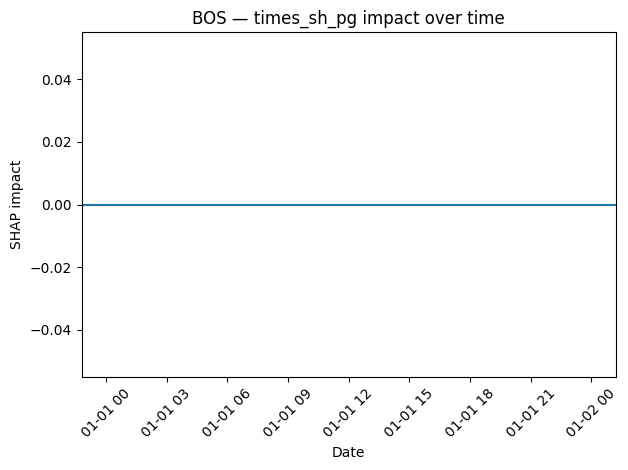

In [220]:
# Build the trend
trends = build_team_feature_trends(shap_summary)

#See season story
get_team_season_drivers(trends, "BOS")

#track a specific feature
plot_feature_trend(shap_summary, "BOS", "times_sh_pg")

“Which features pushed this team above or below the average prediction?”

In [ ]:
shap_df = pd.DataFrame(
    shap_expl.values,
    columns=FEATURE_COLS,
    index=df_present.index
)
shap_df.head()

In [ ]:
latest_idx = (
    df_present
    .sort_values(["team_id", "game_date"])
    .groupby("team_id")
    .tail(1)
    .index
)

shap_latest = shap_df.loc[latest_idx]
meta_latest = df_features.loc[latest_idx]

In [ ]:
def top_negative_drivers(shap_row, n=3):
    sorted_row = shap_row.sort_values()
    return list(zip(sorted_row.index[:n], sorted_row.values[:n]))


In [ ]:
def top_positive_drivers(shap_row, n=3):
    sorted_row = shap_row.sort_values(ascending = False)
    return list(zip(sorted_row.index[:n], sorted_row.values[:n]))

In [ ]:
records = []

for idx, shap_row in shap_latest.iterrows():
    sinks = top_negative_drivers(shap_row, n=3)

    records.append({
        "team_name": meta_latest.loc[idx, "team_name"],
        "tri_code": meta_latest.loc[idx, "tri_code"],
        "season_id": meta_latest.loc[idx, "season_id"],
        "biggest_sinker": f"{sinks[0][0]} ({sinks[0][1]:.3f})",
        "second_biggest_sinker": f"{sinks[1][0]} ({sinks[1][1]:.3f})",
        "third_biggest_sinker": f"{sinks[2][0]} ({sinks[2][1]:.3f})",
        "biggest_sinker_value": sinks[0][1],
    })


In [ ]:
sinker_df = pd.DataFrame(records)

sinker_df = sinker_df.sort_values(
    "team_name"
).reset_index(drop=True)

sinker_df


In [ ]:
help_records = []

for idx, shap_row in shap_latest.iterrows():
    help = top_positive_drivers(shap_row, n=3)

    help_records.append({
        "team_name": meta_latest.loc[idx, "team_name"],
        "tri_code": meta_latest.loc[idx, "tri_code"],
        "season_id": meta_latest.loc[idx, "season_id"],
        "biggest_heloper": f"{help[0][0]} ({help[0][1]:.3f})",
        "second_biggest_helper": f"{help[1][0]} ({help[1][1]:.3f})",
        "third_biggest_helper": f"{help[2][0]} ({help[2][1]:.3f})",
        "biggest_helper_value": help[0][1],
    })


In [ ]:
helper_df = pd.DataFrame(records)

helper_df = helper_df.sort_values(
    "team_name"
).reset_index(drop=True)

helper_df

### 1. Feature Taxonomy Dictionaries

In [ ]:
# ----------------------------------------
# Feature interpretation taxonomy
# v1.5 — pressure-refined + full coverage
# ----------------------------------------

PRESSURE_SENSITIVE = {

    # -------------------------------------------------
    # Special teams & discipline pressure
    # -------------------------------------------------
    "discipline_special_teams": {
        "pk_goals_against_pg",
        "pk_pct",
        "pk_time_on_ice_pg",
        "penalties_taken_pg",
        "c_pp_net_g",
        "times_sh_pg",
        "sh_ga_pg",
        "pk_net_gpg",
        "pk_net_g",
        "pk_net_pct",
        "pk_rank",
        "pp_pct",
        "pp_net_g",
        "pp_net_gpg",
        "pp_net_pct",
        "pp_ga_pg",
        "pp_opp_pg",
        "pk_toi",
        "c_pp_ga",
        "c_times_sh",
        "pk_load_x_pk_pct",
        "sh_gf_pg"
    },

    # -------------------------------------------------
    # Transition fragility
    # -------------------------------------------------
    "transition_volatility": {
        "rush_for_per_game",
        "rush_diff_per_game",
        "rush_against_per_game",
        "rush_shots_against",
        "rush_shots_for",
        "rush_shot_differential",
        "c_rush_shots_for",
        "c_rush_shots_against",
        "c_rush_diff"
    },

    # -------------------------------------------------
    # Close-game execution
    # -------------------------------------------------
    "close_game_execution": {
        "one_goal_win_pct",
        "rotw_pctg",
        "rotw",
        "rw",
        "regulation_wins",
        "ot_wins",
        "ot_losses",
        "so_wins",
        "so_losses",
        "home_otlosses",
        "overtimes",
        "ot_games_pct",
        "game_win"
    },

    # -------------------------------------------------
    # Goal margin stability
    # -------------------------------------------------
    "goal_margin_stability": {
        "goal_diff",
        "goal_diff_pctg",
        "home_goal_diff",
        "road_goal_diff",
        "gd_x_rushdiff"
    },

    # -------------------------------------------------
    # Standings conversion
    # -------------------------------------------------
    "standings_conversion": {
        "points",
        "points_pct",
        "projected_points",
        "win_pct_before",
        "wins_before",
        "wins_pctg",
        "wins",
        "losses",
        "wc2_points"
    },

    # -------------------------------------------------
    # Road resilience
    # Performance under hostile environments
    # -------------------------------------------------
    "road_resilience": {
        "road_goal_diff",
        "road_points",
        "road_rw",
        "road_rotw",
        "road_wins",
        "road_losses",
        "road_ot_losses",
        "road_gf",
        "road_ga"
    },

    # -------------------------------------------------
    # Possession stress response
    # -------------------------------------------------
    "possession_under_pressure": {
        "c_shot_pct",
        "corsi_diff_per_game",
        "c_corsi_diff",
        "corsi_diff",
        "c_pdo",
        "shots_diff_per_game",
        "shot_attempts_differential"
    },

    # -------------------------------------------------
    # Short-horizon momentum
    # -------------------------------------------------
    "recent_form": {
        "last_10_rw",
        "last_10_goal_diff",
        "last_10_points",
        "last_10_ga",
        "last_10_gf",
        "last_10_wins",
        "last_10_losses",
        "last_10_otl",
        "last_10_rotw",
        "last_10_gp",
        "streak_count",
        "streak_signed"
    }

}


PRESSURE_AGNOSTIC = {

    # -------------------------------------------------
    # Possession & shot generation
    # -------------------------------------------------
    "possession_generation": {
        "corsi_for_pg",
        "shots_for_pg",
        "SCF_pg",
        "corsi_for",
        "c_corsi_for",
        "c_shots_for",
        "c_shots_diff",
        "shot_attempts_for",
        "shot_attempts_for_per_game",
        "shot_pct"
    },

    # -------------------------------------------------
    # Defensive suppression
    # -------------------------------------------------
    "defensive_suppression": {
        "corsi_against",
        "c_corsi_against",
        "c_shots_against",
        "shot_attempts_against",
        "shot_attempts_against_per_game",
        "shots_against_pg"
    },

    # -------------------------------------------------
    # Chance creation
    # -------------------------------------------------
    "chance_creation": {
        "xGF_pg",
        "SCF",
        "SCSF",
        "SCGF",
        "c_SCF",
        "c_SCSF",
        "c_SCGF",
        "HDCF",
        "HDCF_pct",
        "c_HDCF",
        "c_MDCF",
        "MDCF",
        "MDCF_pct",
        "c_LDCF",
        "LDCF",
        "LDCF_pct"
    },

    # -------------------------------------------------
    # Chance suppression
    # -------------------------------------------------
    "chance_suppression": {
        "SCA",
        "SCA_pg",
        "c_SCA",
        "HDCA",
        "c_HDCA",
        "HDCA_pct",
        "MDCA",
        "c_MDCA",
        "MDCA_pct",
        "LDCA",
        "c_LDCA",
        "LDCA_pct",
        "c_ld_against",
        "c_md_against",
        "c_hd_against"
    },

    # -------------------------------------------------
    # Shot quality detail
    # -------------------------------------------------
    "shot_quality_detail": {
        "c_hd_sog",
        "c_md_sog",
        "c_ld_sog",
        "c_hd_goals",
        "c_md_goals",
        "c_ld_goals"
    },

    # -------------------------------------------------
    # Offensive baseline scoring
    # -------------------------------------------------
    "offensive_output": {
        "goals_for_pg",
        "gf_pctg",
        "c_goals_for",
        "home_gf",
        "road_gf"
    },

    # -------------------------------------------------
    # Defensive scoring suppression
    # -------------------------------------------------
    "defensive_output": {
        "c_goals_against",
        "home_ga",
        "road_ga"
    },

    # -------------------------------------------------
    # Special teams baseline talent
    # -------------------------------------------------
    "special_teams_offense": {
        "pp_goals_pg",
        "pp_gpg",
        "pp_toi",
        "pp_opp",
        "c_pp_opps",
        "ppng_rank"
    },

    # -------------------------------------------------
    # Goaltending baseline talent
    # -------------------------------------------------
    "goaltending_baseline": {
        "c_sv_pct",
        "sv_pct",
        "gaa_x_sv",
        "pdo"
    }

}


EXOGENOUS_PRESSURE = {

    # -------------------------------------------------
    # Standings position
    # -------------------------------------------------
    "standings_position": {
        "division_rank",
        "conference_rank",
        "wildcard_rank",
        "conference_team_count",
        "in_playoff_spot",
        "in_div_top3",
        "in_wc_spot",
        "on_wc_bubble"
    },

    # -------------------------------------------------
    # Playoff probability context
    # -------------------------------------------------
    "playoff_probability": {
        "conf_playoff_chance_baseline"
    },

    # -------------------------------------------------
    # Wildcard race geometry
    # -------------------------------------------------
    "wildcard_race_density": {
        "wc_points_margin",
        "wc_points_pct_margin",
        "wc_teams_within_2pts",
        "wc_teams_within_4pts",
        "wc_teams_within_6pts",
        "wc2_points_pct"
    },

    # -------------------------------------------------
    # Schedule difficulty
    # -------------------------------------------------
    "schedule_strength": {
        "sos_future",
        "sos_past"
    },

    # -------------------------------------------------
    # Season clock
    # -------------------------------------------------
    "season_clock": {
        "games_remaining",
        "games_played",
        "games_before"
    }

}


CONTEXT_AMPLIFIED_EXECUTION = {

    # -------------------------------------------------
    # Standings leverage
    # -------------------------------------------------
    "standings_leverage": {
        "points_pct",
        "projected_points"
    },

    # -------------------------------------------------
    # Margin compression
    # -------------------------------------------------
    "goal_margin_pressure": {
        "goal_diff_pctg"
    },

    # -------------------------------------------------
    # Schedule-adjusted performance
    # -------------------------------------------------
    "schedule_adjusted_performance": {
        "pt_pct_x_sos"
    },

    # -------------------------------------------------
    # Possession under leverage
    # -------------------------------------------------
    "possession_under_leverage": {
        "corsi_diff_per_game",
        "c_corsi_diff",
        "c_shot_pct"
    },

    # -------------------------------------------------
    # Transition margin leverage
    # -------------------------------------------------
    "transition_margin_pressure": {
        "rush_for_per_game",
        "rush_diff_per_game"
    },

    # -------------------------------------------------
    # Venue leverage
    # -------------------------------------------------
    "venue_leverage": {
        "home_goal_diff",
        "home_losses",
        "home_rw",	
        "home_rotw",
        "home_wins",
        "home_points",	

    },

    # -------------------------------------------------
    # League structure context
    # -------------------------------------------------
    "league_structure_context": {
        "conference_team_count",
        "road_gp",
        "home_gp"
    }

}

### 2. Build Taxonomy Lookup

In [ ]:

# ----------------------------------------
# 2. Build the taxonomy lookup table
# ----------------------------------------

FEATURE_TAXONOMY = {}

for category, groups in {
    "Pressure-Sensitive": PRESSURE_SENSITIVE,
    "Pressure-Agnostic": PRESSURE_AGNOSTIC,
    "Environment": EXOGENOUS_PRESSURE,
    "Context-Amplified": CONTEXT_AMPLIFIED_EXECUTION
}.items():

    for subcategory, features in groups.items():
        for feature in features:
            FEATURE_TAXONOMY[feature] = (category, subcategory)


### 3. Classify Features

In [ ]:
def classify_feature(feature):

    for sublabel, features in EXOGENOUS_PRESSURE.items():
        if feature in features:
            return "Environment", sublabel

    for sublabel, features in PRESSURE_SENSITIVE.items():
        if feature in features:
            return "Pressure-Sensitive", sublabel

    for sublabel, features in PRESSURE_AGNOSTIC.items():
        if feature in features:
            return "Pressure-Agnostic", sublabel

    for sublabel, features in CONTEXT_AMPLIFIED_EXECUTION.items():
        if feature in features:
            return "Context-Amplified", sublabel

    return "Unclassified", None

### 4. SHAP by Category

In [ ]:
def shap_by_category(shap_series, FEATURE_TAXONOMY):

    df = shap_series.reset_index()
    df.columns = ["feature", "impact"]

    df["category"] = df["feature"].map(
        lambda f: FEATURE_TAXONOMY.get(f, ("Unclassified", None))[0]
    )

    df["subcategory"] = df["feature"].map(
        lambda f: FEATURE_TAXONOMY.get(f, ("Unclassified", None))[1]
    )

    return (
        df.groupby(["category", "subcategory"], dropna=False)["impact"]
        .sum()
        .sort_values()
    )
    


### 5. Feature Descriptions Dictionary

In [ ]:
FEATURE_DESCRIPTIONS  = {
    "pk_pct": "Penalty kill success rate",
    "pk_goals_against_pg": "PK goals allowed per game",
    "rush_against_per_game": "Rush chances allowed per game",
    "rush_for_per_game": "Rush chances generated per game",
    "goal_diff_pctg": "Goal differential percentage",
    "points_pct": "Points percentage",
    "projected_points": "Projected season points",
    "corsi_diff_per_game": "Corsi differential per game",
    "c_shot_pct": "Corsi shot share",
    "sos_future": "Strength of remaining schedule",
    "SCF_pg": "Shooting chances for per game",
    "c_sv_pct": "Cumulative save percentage",
    "home_goal_diff": "Goal differential at home",
    "goal_diff" : "Overall goal differential",
    "wins_pctg": "Percent of games that are wins",
    "ot_games_pct": "Percent of games that go into overtime",
    "so_losses": "Shootout losses",
    "ppng_rank": "League rank in net PPG",
    "wc_points_margin": "distance from the playoff cutoff line in the wildcard race",
    "win_pct_before": "Win percentage before the most recent snapshot",
    "c_pp_net_g": "Cumulative net PPG",
    "shots_diff_per_game": "Average shot differential per game",
    "c_shots_diff": "Cumulative shot differential",
    "gf_pctg": "Share of total goals in a team's games that were scored by that team",
    "road_goal_diff": "Goal differential on the road",
    "pk_rank": "League rank in PK",
    "shot_attempts_against_per_game": "Average number of shot attempts against per game",
    "SCA_pg": "Average scoring chances against per game",
    "c_pdo": "Cumulative puck-luck indicator",
    "road_rw": "Regulation wins on the road",
    "shot_attempts_for_per_game": "Average number of shot attempts made by the team per game",
    "road_losses": "Road loss",
    "c_rush_diff": "Cumulative rush chances differential",
    "home_losses": "Home loss",
    "sos_past": "Strength of schedule thus far in the season",
    "overtimes": "Count of overtime games",
    "rw": "Regulation win",
    "c_times_sh": "Cumulative times shorthanded",
    "rush_diff_per_game": "Average rush chances differential per game",
    "c_rush_shots_against": "Cumulative rush shots against",
    "road_ga": "Road games goals allowed",
    "c_pp_ga": "Cumulative goals allowed when on the PK",
    "rotw_pctg": "Regulation and OT win percentage",
    
    
    
}

### 6. Team Robustness Breakdown

In [ ]:
def team_robustness_breakdown(
    team_code,
    df_present,
    shap_df,
    taxonomy
):
    """
    Quantifies how much a team's negative SHAP impact
    comes from environment vs pressure-sensitive performance.
    """

    # Locate latest snapshot
    team_rows = df_present[df_present["tri_code"] == team_code]
    if team_rows.empty:
        raise ValueError(f"{team_code} not found")

    row_idx = team_rows.sort_values("game_date").index[-1]
    shap_row = shap_df.loc[row_idx]

    # Only negative contributors
    negative = shap_row[shap_row < 0]

    records = []

    for feature, value in negative.items():

        category, subcategory = taxonomy.get(
            feature,
            ("Unclassified", None)
        )

        records.append({
            "feature": feature,
            "impact": value,
            "category": category,
            "subcategory": subcategory
        })

    df = pd.DataFrame(records)

    # Summary by major category
    summary_category = (
        df.groupby("category")["impact"]
        .sum()
        .sort_values()
    )

    # Summary by subcategory
    summary_subcategory = (
        df.groupby(["category","subcategory"])["impact"]
        .sum()
        .sort_values()
    )

    return (
        df.sort_values("impact"),
        summary_category,
        summary_subcategory
    )

##### Call Robustness

In [ ]:
detail, summary_category, summary_subcategory = team_robustness_breakdown(
    team_code="BOS",
    df_present=df_present,
    shap_df=shap_df,
    taxonomy=FEATURE_TAXONOMY
)

print("📉 Negative SHAP impact by category:")
display(summary_category)

print("\n📊 Negative SHAP impact by subcategory:")
display(summary_subcategory)

print("\n🔍 Biggest individual sinkers:")
display(detail.head(10))

### 7. Pressure Leverage Table

In [ ]:
def build_pressure_leverage_table(shap_row, FEATURE_DESCRIPTIONS):
    """
    Build a table showing how each feature contributes to pressure leverage
    using SHAP values and the feature taxonomy metadata.
    """

    records = []

    for feature, shap_value in shap_row.items():

        category, subcategory = classify_feature(feature)

        records.append({
            "feature": feature,
            "impact": shap_value,
            "abs_impact": abs(shap_value),
            "category": category,
            "subcategory": subcategory,
            "description": FEATURE_DESCRIPTIONS.get(feature, None)
        })

    df = pd.DataFrame(records)

    # Sort by strongest SHAP influence
    df = df.sort_values("abs_impact", ascending=False)

    return df

##### Call Pressure Leverage Table

In [ ]:
leverage = build_pressure_leverage_table(shap_row, FEATURE_DESCRIPTIONS)
# leverage[leverage['category']=="Unclassified"]
leverage.head()


How to read it

High fixability + large negative SHAP = coaching / systems leverage

Medium fixability = tactical emphasis

Environment = context, not blame

This table answers:

“If XYZ team improves just two things, what should they be?”

### 8. Pressure Sensitivity Score

“How fragile is this team in a tight race?”

This becomes a single number you can track over time. Pressure Sensitivity Score =
(sum of negative Pressure-Sensitive SHAP) ÷ (total negative SHAP)

In [ ]:
def pressure_sensitivity_score(shap_series, FEATURE_TAXONOMY):
    neg = shap_series[shap_series < 0]

    total_neg = neg.sum()
    if total_neg == 0:
        return 0.0

    pressure_categories = {"Pressure-Sensitive", "Context-Amplified"}

    ps_neg = neg[
        neg.index.map(
            lambda f: FEATURE_TAXONOMY.get(f, ("", ""))[0]
        ).isin(pressure_categories)
    ].sum()

    return float(ps_neg / total_neg)

Interpretation guide:
Score	Meaning
- < 0.25	Stable contender
- 0.25–0.45	Normal playoff pressure
- 0.45–0.65	Bubble-fragile
- "> 0.65"	Execution-dependent team

Boston being high here = race amplifies weaknesses

##### Call Pressure Sensitivity

In [ ]:
ps_score = pressure_sensitivity_score(shap_row, FEATURE_TAXONOMY)
ps_score


### 10. Call Shap by Category
#### Environmental vs Execution Visual


“Is this luck or performance?”

This is the chart that tells the story instantly.

In [ ]:
cat_impact = shap_by_category(shap_row, FEATURE_TAXONOMY)
cat_impact

In [ ]:
# # convert MultiIndex → readable labels
#     if isinstance(cat_impact.index, pd.MultiIndex):
#         cat_impact.index = [
#             f"{sub}" if sub else cat
#             for cat, sub in cat_impact.index
#         ]

plot_df = cat_impact.reset_index()
category_colors = {
    "Pressure-Sensitive": "#d62728",
    "Pressure-Agnostic": "#2ca02c",
    "Environment": "#1f77b4",
    "Context-Amplified": "#ff7f0e",
    "Unclassified": "#7f7f7f"
}

plot_df["color"] = plot_df["category"].map(category_colors)
plot_df["label"] = plot_df["subcategory"].fillna(plot_df["category"])
plot_df

In [ ]:
from matplotlib.patches import Patch

if cat_impact.empty:
    print("No SHAP impacts available to plot.")
else:

    plot_df = cat_impact.reset_index()

    # y-axis label
    plot_df["label"] = plot_df["subcategory"].fillna(plot_df["category"])

    category_colors = {
        "Pressure-Sensitive": "#d62728",
        "Pressure-Agnostic": "#2ca02c",
        "Environment": "#1f77b4",
        "Context-Amplified": "#ff7f0e",

    }

    plot_df["color"] = plot_df["category"].map(category_colors)

    plot_df = plot_df.sort_values("impact")

    plt.figure(figsize=(9,6))

    plt.barh(
        plot_df["label"],
        plot_df["impact"],
        color=plot_df["color"]
    )

    plt.axvline(0, color="black", linewidth=1)

    plt.title("Playoff Prediction Drivers (SHAP by Category)", fontsize=13)
    plt.xlabel("Total SHAP Impact")
    legend_elements = [
        Patch(facecolor=color, label=category)
        for category, color in category_colors.items()
    ]

    plt.legend(
        handles=legend_elements,
        title="Driver Type",
        loc="lower right"
    )
    plt.tight_layout()
    plt.show()

How to read it

Pressure-Sensitive dominating → fixable execution issues

Environment dominating → schedule / race reality

Pressure-Agnostic dominating → roster ceiling issues

“This team is hurting itself more than the league is hurting it.”

≥ 0.85  → High-confidence territory
0.65–0.85 → Solid contender
0.45–0.65 → True bubble
0.25–0.45 → Outside but alive
< 0.25 → Long shot


In [ ]:
def playoff_tier(prob, pressure_sensitivity):
    if prob >= 0.85 and pressure_sensitivity <= 0.40:
        return "Lock"
    elif prob >= 0.65 and pressure_sensitivity <= 0.45:
        return "Likely"
    elif prob >= 0.45:
        return "Bubble"
    elif prob >= 0.25 and pressure_sensitivity > 0.30:
        return "Likely Out"
    else:
        return "Out"


In [ ]:
latest_snapshot = (
    df_features
    .sort_values(["team_id", "game_date"])
    .groupby("team_id", as_index=False)
    .tail(1)
)

latest_snapshot.head()

In [ ]:
latest_snapshot["playoff_tier"] = latest_snapshot.apply(
    lambda r: playoff_tier(
        r["playoff_prob_display"],
        r["pressure_sensitivity_score"]
    ),
    axis=1
)
